## CMF-BO-GP 7.1

### Function 7 - Hyperparameters

You’re tasked with optimising an ML model by tuning six hyperparameters, for example learning rate, regularisation strength or number of hidden layers. The function you’re maximising is the model’s performance score (such as accuracy or F1), but since the relationship between inputs and output isn’t known, it’s treated as a black-box function. 
Because this is a commonly used model, you might benefit from researching best practices or literature to guide your initial search space. Your goal is to find the combination of hyperparameters that yields the highest possible performance.


### Components to the model
#### 1. Import libraries
#### 2. Import and Analyse data - combining baseline data with new queries; then performing statistical analysis on the combined data
#### 3. Visualising data - create a 2D view with showing baseline, additional queries and current maxima - and a 3D representation.
#### 4. Core Model - v1 - UCB / EI models - with length scales and bounds
#### 5. Expliotation model - for final queries to maximise outputs (from scipy.optimize import minimize)

In [3]:
# ==============================================
# 1. Import required libraries to support model
# ==============================================

import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from IPython.display import clear_output
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from scipy.stats import norm
from scipy.interpolate import griddata

In [4]:
# ====================================
# 2. Import and Analyse the data set  
# ====================================

# 1. Load 6D spatial coordinate data and output values
inputs = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC7/initial_inputs.npy')
output = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC7/initial_outputs.npy')

print(f"Base Maximia: ",output.max())

extra_inputs = [[0.029217, 0.445624, 0.284957, 0.173546, 0.367695, 0.732927],
                [0.104372, 0.225659, 0.433356, 0.136422, 0.338113, 0.943647],
                [0.000000, 0.267792, 0.069571, 0.000000, 0.227411, 0.803541],
                [0.001724, 0.382795, 0.427673, 0.142881, 0.342742, 0.752438],
                [0.000000, 0.453311, 0.438465, 0.069844, 0.341572, 0.763047],
                [0.006345, 0.293373, 0.396797, 0.244223, 0.348086, 0.733486],
                [0.005211, 0.293373, 0.396797, 0.221541, 0.362141, 0.785230],
                [0.000000, 0.203680, 0.650701, 0.281315, 0.329023, 0.683525],
               	[0.000000, 0.232237, 0.595069, 0.273864, 0.333299, 0.695738],
                [0.000000, 0.252933, 0.560968, 0.274424, 0.333953, 0.698232],
                [0.000000, 0.252999, 0.558600, 0.274497, 0.333784, 0.698943],
                [0.000000, 0.241408, 0.534982, 0.276596, 0.329902, 0.707627],
               ]
extra_output = [1.6212926285983933,1.3627627244158926,0.7161023344103655,
                1.8414404584309458,1.3053428311606587,2.4255002691625127,
               2.1460336008706697,2.544740511527827,2.6317852796995407,
               	2.6477290379593588,2.6495887706567354,2.6813772076164475]

inputs = np.vstack([inputs, extra_inputs])
output = np.append(output, extra_output)


print(f"Current Maxima: ",output.max())


# 2. Combine into a single Pandas DataFrame
df = pd.DataFrame(inputs, columns=['Input_U','Input_V','Input_W','Input_X', 'Input_Y', 'Input_Z'])
df['Output_Target'] = output

# 3. Compute the correlation matrix
# Change method to 'spearman' if relationships are non-linear curves
corr_matrix = df.corr(method='pearson')

# 4. Isolate how each input correlates *only* with the target output
target_corr = corr_matrix['Output_Target'].drop('Output_Target')

print("Correlation with Output:")
print(target_corr)

# Calculate non-linear relationship dependency (higher score = stronger relationship)
mi_scores = mutual_info_regression(inputs, output)

for name, score in zip(['Input_U','Input_V','Input_W','Input_X', 'Input_Y', 'Input_Z'], mi_scores):
    print(f"{name} Mutual Information Score: {score:.4f}")


# Fit a quick non-linear model that checks all 4 dimensions simultaneously
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(inputs, output)

# Extract total feature importances (including interactions)
importances = model.feature_importances_

for name, score in zip(['Input_U','Input_V','Input_W','Input_X', 'Input_Y', 'Input_Z'], importances):
    print(f"{name} Total Importance (with interactions): {score:.4f}")

Base Maximia:  1.3649683044991994
Current Maxima:  2.6813772076164475
Correlation with Output:
Input_U   -0.667409
Input_V   -0.204394
Input_W    0.216878
Input_X   -0.383360
Input_Y   -0.290739
Input_Z    0.452465
Name: Output_Target, dtype: float64
Input_U Mutual Information Score: 0.4467
Input_V Mutual Information Score: 0.3386
Input_W Mutual Information Score: 0.2112
Input_X Mutual Information Score: 0.3955
Input_Y Mutual Information Score: 0.5337
Input_Z Mutual Information Score: 0.5842
Input_U Total Importance (with interactions): 0.8089
Input_V Total Importance (with interactions): 0.0218
Input_W Total Importance (with interactions): 0.0167
Input_X Total Importance (with interactions): 0.0912
Input_Y Total Importance (with interactions): 0.0140
Input_Z Total Importance (with interactions): 0.0475


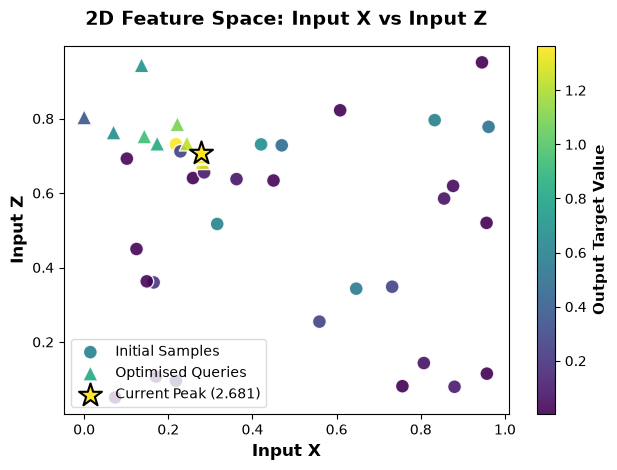

In [5]:
# ===================================
# 3.1 Visualise the data set X and Z
# ===================================

# Find the coordinates of the maximum value dynamically
max_row_index = df['Output_Target'].idxmax()
max_y = df.loc[max_row_index, 'Input_X']
max_z = df.loc[max_row_index, 'Input_Z']
max_val = df.loc[max_row_index, 'Output_Target']



# Create scatter plot with the first 30 smaples
scatter1 = plt.scatter(
    data=df.iloc[:30], 
    x='Input_X', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=100,            # Marker size
    edgecolor='w',    # White border around markers
    alpha=0.9
)

# Plot the next query samples (e.g., as triangles '^')
scatter2 = plt.scatter(
    data=df.iloc[30:len(output)], 
    x='Input_X', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=120,            # Made slightly larger so triangles stand out nicely
    edgecolor='w',    
    alpha=0.9,
    marker='^',       # <--- Shape for the next 9 points
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max()
)

scatter3 = plt.scatter(
    x=max_y, 
    y=max_z, 
    c=[max_val],   
    cmap='viridis',    # Highly visible contrasting color
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max(),
    s=300,            # Much larger marker size to make it pop
    marker='*',       # Star shape
    edgecolor='black',
    linewidth=1.5,
    label=f'Current Max ({max_val:.2f})',
    zorder=5          # Ensures it sits on top of all other points
)


# Add elements
cbar = plt.colorbar(scatter1)
cbar.set_label('Output Target Value', fontsize=11, fontweight='bold')
plt.xlabel('Input X', fontsize=12, fontweight='bold')
plt.ylabel('Input Z', fontsize=12, fontweight='bold')
plt.title('2D Feature Space: Input X vs Input Z', fontsize=14, fontweight='bold', pad=15)

plt.legend(
    handles=[scatter1, scatter2,scatter3], 
    labels=['Initial Samples', 'Optimised Queries', f'Current Peak ({max_val:.3f})'],
    loc='lower left', 
    frameon=True, 
    facecolor='white', 
    edgecolor='lightgray', 
    fontsize=10
)
plt.tight_layout()
plt.show()

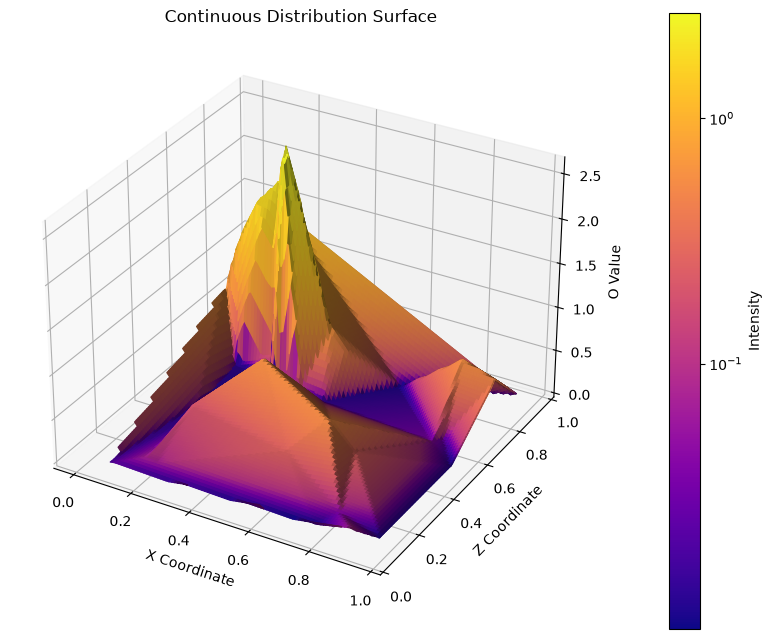

In [6]:
# ===================================
# 3.2. Visualise the data set 3D
# ===================================


coords = (inputs[:,3],inputs[:,5])

# Define a regular 2D grid based on your data boundaries
grid_x, grid_y = np.meshgrid(
    np.linspace(coords[0].min(), coords[0].max(), 100),
    np.linspace(coords[1].min(), coords[1].max(), 100)
)

# Interpolate the scattered (x, y, z) data onto the uniform grid
# Options for method: 'linear', 'cubic', or 'nearest'
grid_z = griddata((coords[0], coords[1]), output, (grid_x, grid_y), method='linear')

# If your y_clean variable is different from values, interpolate it too for the colors
grid_color = griddata((coords[0], coords[1]), output, (grid_x, grid_y), method='linear')

# Create the 3D surface plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
norm = colors.SymLogNorm(linthresh=0.1, vmin=output.min(), vmax=output.max())


# Plot the continuous surface
# facecolors overrides standard mapping to use your output
surf = ax.plot_surface(
    grid_x, grid_y, grid_z,
    facecolors=plt.cm.plasma(norm(grid_color)),
    rcount=100, ccount=100,  # Grid resolution
    antialiased=True,
    shade=True
)

# Design elements
# Create a dummy scalar mappable object just to display the colorbar correctly
mappable = plt.cm.ScalarMappable(cmap='plasma', norm=norm)
fig.colorbar(mappable, ax=ax, label="Intensity", pad=0.1)

ax.set_xlabel("X Coordinate")
ax.set_ylabel("Z Coordinate")
ax.set_zlabel("O Value")
ax.set_title("Continuous Distribution Surface")

plt.show()

In [ ]:
# ===========================================
# 4 (v1) GP Model - with UCB/EI 
# ===========================================

import numpy as np
from sklearn.ensemble import RandomForestRegressor

# Train a predictive model on your 30 existing samples
predictor = RandomForestRegressor(n_estimators=100, random_state=42)
predictor.fit(inputs, output)

def objective_6d(X):
    """
    Surrogate function for 6D optimization.
    X: A 2D numpy array of shape (n_samples, 6) sent by the optimizer.
    """
    # Force input to be 2D array matrix for sklearn compatibility
    X = np.atleast_2d(X)
    
    # Predict the output value using the trained model
    predictions = predictor.predict(X)
    
    # Return as a flat 1D array as expected by your code (.ravel())
    return predictions.ravel()

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern, ConstantKernel as C
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

def upper_confidence_bound(mu, sigma, kappa=0.1):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma


def expected_improvement(mu, sigma, y_best, xi=0.01):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei

In [7]:
def bayesian_optimization_nd(objective_func, n_dims, n_iterations=1, 
                            n_initial=5, acquisition='ei'):
    """
    Bayesian Optimization for n-dimensional functions.
    Assumes bounds [0, 1] for all dimensions.
    """
    bounds = [(0, 1) for _ in range(n_dims)]
    
    # Initialize
    X_samples = inputs
    y_samples = output

    initial_length_scales = np.array([
        0.10,  # Input_U: Hyper-critical foundation, requires micro-adjustments
        1.00,  # Input_V: Passive parameter, smooth it out completely
        1.00,  # Input_W: Passive parameter, smooth it out completely
        0.30,  # Input_X: Moderate importance
        0.30,  # Input_Y: High non-linear importance, requires precise sweet-spotting
        0.15   # Input_Z: Strong positive accelerator, push boundaries carefully
    ])
    length_scale_bounds = [(1e-2, 1e2) for _ in range(n_dims)]
    
    best_values = [y_samples.max()]
    
    print(f"Starting {n_dims}D optimization with {n_initial} initial samples...")
    print(f"Initial best: {y_samples.max():.4f}\n")
      
    
    for iteration in range(n_iterations):
        # Fit GP
        ard_kernel = C(1.0, (1e-3, 1e3)) * Matern(
            length_scale=initial_length_scales, 
            length_scale_bounds=length_scale_bounds, 
            nu=2.5  # nu=2.5 enforces Matérn 5/2 behavior
            )
        gp = GaussianProcessRegressor(kernel=ard_kernel, alpha=1e-6,normalize_y=True,
                                     n_restarts_optimizer=10)
        gp.fit(X_samples, y_samples)

        # Optimize acquisition function
        def acq_objective(X):
            X = X.reshape(1, -1)
            mu, sigma = gp.predict(X, return_std=True)
            
            if acquisition == 'ei':
                acq_val = expected_improvement(mu, sigma, y_samples.max())
            else:
                acq_val = upper_confidence_bound(mu, sigma, kappa=0.5)
           
            return -acq_val
        
        # Multi-start optimization
        best_acq = np.inf
        X_next = None
        
        for _ in range(50):  # More starts for higher dimensions
            x0 = np.random.uniform(0, 1, n_dims)
            result = minimize(acq_objective, x0, bounds=bounds, method='L-BFGS-B')
            if result.fun < best_acq:
                best_acq = result.fun
                X_next = result.x
                print(f"Optimized Next Point Found! Predicted Acquisition Score: {-best_acq:.6f}")
                print(f"Coordinates to test next: {X_next}")

       
        # Evaluate
        y_next = objective_func(X_next.reshape(1, -1)).ravel()
        
        # Update
        X_samples = np.vstack([X_samples, X_next])
        y_samples = np.append(y_samples, y_next)
        best_values.append(y_samples.max())
        
        if (iteration + 1) % 10 == 0:
            print(f"Iteration {iteration + 1}: Best f(x)={y_samples.max():.4f}")
    
    return X_samples, y_samples, best_values



# Run 6D optimization
X_samples_6d, y_samples_6d, best_values_6d = bayesian_optimization_nd(
    objective_6d, 
    n_dims=6,
    n_iterations=3,
    acquisition=''
)


Starting 6D optimization with 5 initial samples...
Initial best: 2.6814

Optimized Next Point Found! Predicted Acquisition Score: 2.757666
Coordinates to test next: [0.         0.1490514  0.47764861 0.2852523  0.32853295 0.69977375]
Optimized Next Point Found! Predicted Acquisition Score: 2.757666
Coordinates to test next: [0.         0.14905156 0.47764879 0.2852524  0.328533   0.69977385]
Optimized Next Point Found! Predicted Acquisition Score: 2.734368
Coordinates to test next: [0.         0.22336861 0.53882828 0.30699378 0.30831728 0.73215117]
Optimized Next Point Found! Predicted Acquisition Score: 2.734368
Coordinates to test next: [0.         0.22336872 0.53882778 0.30699402 0.30831758 0.73215123]
Optimized Next Point Found! Predicted Acquisition Score: 2.734368
Coordinates to test next: [0.         0.22336858 0.53882762 0.3069938  0.30831731 0.73215122]
Optimized Next Point Found! Predicted Acquisition Score: 2.841734
Coordinates to test next: [0.         0.09326366 0.56379133 0

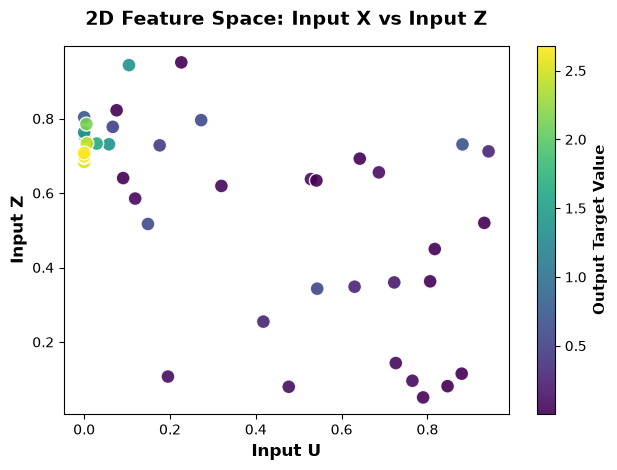

In [7]:
# ============================================
# 5. Exploitation Model - scipy.optimize
# ============================================

import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C
from scipy.optimize import minimize

# 1. Load the 6D dataset (Features: U, V, W, X, Y, Z)
X_train = inputs
y_train = output

# 2. Configure a Matern GP Surrogate Model
# Matern nu=1.5 allows for the distinct "cliffs" visible when U shifts off 0.0.
kernel = C(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(6), length_scale_bounds=(1e-2, 10.0), nu=1.5)
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=25, alpha=1e-6, random_state=42)

# Fit model to historical space
gp.fit(X_train, y_train)

# 3. Formulate Optimization Target (Negative prediction for minimization algorithm)
def objective(x):
    # Predict returns shape (1, 6), flatten to extract scalar
    return -float(gp.predict(x.reshape(1, -1))[0])

# 4. Enforce Bounding Box System limits [0.0, 1.0]
bounds = [
    (0.0, 0.05),   # U: Aggressively bounded close to its zero cliff
    (0.15, 0.35),  # V
    (0.45, 0.80),  # W
    (0.15, 0.35),  # X
    (0.25, 0.45),  # Y
    (0.60, 0.85)   # Z
]

# Use your historical peak coordinate as the optimization warm-start point
x_start = np.array([0.0, 0.20368, 0.650701, 0.281315, 0.329023, 0.683525])

# 5. Execute L-BFGS-B Optimization Local Search
result = minimize(objective, x_start, method='L-BFGS-B', bounds=bounds)

# 6. Display Predicted Coordinates
print("--- GAUSSIAN PROCESS TARGET PREDICTION ---")
print(f"Predicted Max Output: {abs(result.fun):.4f}")
print("Optimal Coordinates:")
for name, val in zip(['U', 'V', 'W', 'X', 'Y', 'Z'], result.x):
    print(f"  Input_{name}: {val:.6f}")

--- GAUSSIAN PROCESS TARGET PREDICTION ---
Predicted Max Output: 2.6964
Optimal Coordinates:
  Input_U: 0.000000
  Input_V: 0.216120
  Input_W: 0.513268
  Input_X: 0.280408
  Input_Y: 0.324442
  Input_Z: 0.713453
